# Emotion Detection from Facial Expressions using Convolutional Neural Networks

**Dataset:** FER-2013 (`msambare/fer2013`, Kaggle) — 35,887 grayscale 48x48 face images, 7 emotion classes.

This notebook walks through the whole pipeline: data loading, exploration, the CNN architecture,
training, and evaluation (accuracy + confusion matrix).

In [1]:
import os, sys
root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath(os.getcwd())
sys.path.insert(0, root)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
from src import config
print('Project root :', root)
print('Emotions     :', config.EMOTIONS)

Project root : H:\Emotion Detection Project - DEEP LEARNING
Emotions     : ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']


## 1. Load the FER-2013 dataset

In [2]:
from src.dataset import load_fer2013_csv, class_distribution
(X_train, y_train), (X_test, y_test) = load_fer2013_csv()
print('train:', X_train.shape, 'test:', X_test.shape)
print('train distribution:', class_distribution(y_train))

train: (28709, 48, 48, 1) test: (7178, 48, 48, 1)
train distribution: {'angry': 3995, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'sad': 4830, 'surprise': 3171, 'neutral': 4965}


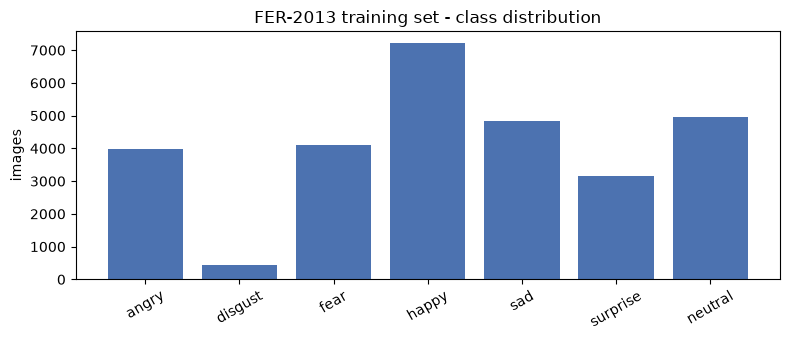

In [3]:
# Class distribution
dist = class_distribution(y_train)
plt.figure(figsize=(8, 3.5))
plt.bar(list(dist.keys()), list(dist.values()), color='#4C72B0')
plt.title('FER-2013 training set - class distribution')
plt.ylabel('images'); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

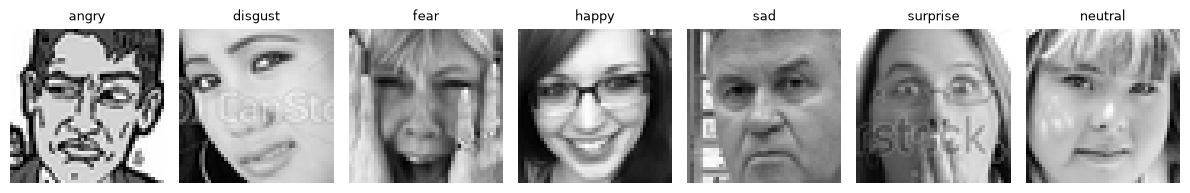

In [4]:
# One sample face per emotion
fig, axes = plt.subplots(1, 7, figsize=(12, 2.2))
for i, name in enumerate(config.EMOTIONS):
    idx = int(np.where(y_test == i)[0][0])
    axes[i].imshow(X_test[idx].reshape(48, 48), cmap='gray')
    axes[i].set_title(name, fontsize=9); axes[i].axis('off')
plt.tight_layout(); plt.show()

## 2. CNN architecture

In [5]:
from src.model import build_cnn
model = build_cnn()
model.summary()

Model: "emotion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ face (InputLayer)               │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rot (RandomRotation)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_shift (RandomTranslation)   │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_zoom (RandomZoom)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,470,247 (5.61 MB)

 Trainable params: 1,468,839 (5.60 MB)

 Non-trainable params: 1,408 (5.50 KB)

## 3. Load the trained model and evaluate

The model was trained with `python -m src.train`. Remove the lines below and call `src.train.main()` to retrain from scratch.

In [6]:
from src.model import load_trained_model
model = load_trained_model()
print('Loaded:', config.MODEL_PATH)

Loaded: H:\Emotion Detection Project - DEEP LEARNING\models\emotion_cnn_fer2013.keras


In [7]:
probs = model.predict(X_test, batch_size=256, verbose=0)
y_pred = np.argmax(probs, axis=1)
acc = (y_pred == y_test).mean()
print(f'Test accuracy: {acc*100:.2f}%')

Test accuracy: 63.78%


In [8]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred, target_names=config.EMOTIONS, digits=4))
cm = confusion_matrix(y_test, y_pred)

              precision    recall  f1-score   support

       angry     0.5504    0.5647    0.5574       958
     disgust     0.7302    0.4144    0.5287       111
        fear     0.4892    0.4189    0.4513      1024
       happy     0.8350    0.8670    0.8507      1774
         sad     0.5465    0.4050    0.4652      1247
    surprise     0.7135    0.8002    0.7544       831
     neutral     0.5485    0.6926    0.6122      1233

    accuracy                         0.6378      7178
   macro avg     0.6305    0.5947    0.6029      7178
weighted avg     0.6327    0.6378    0.6305      7178



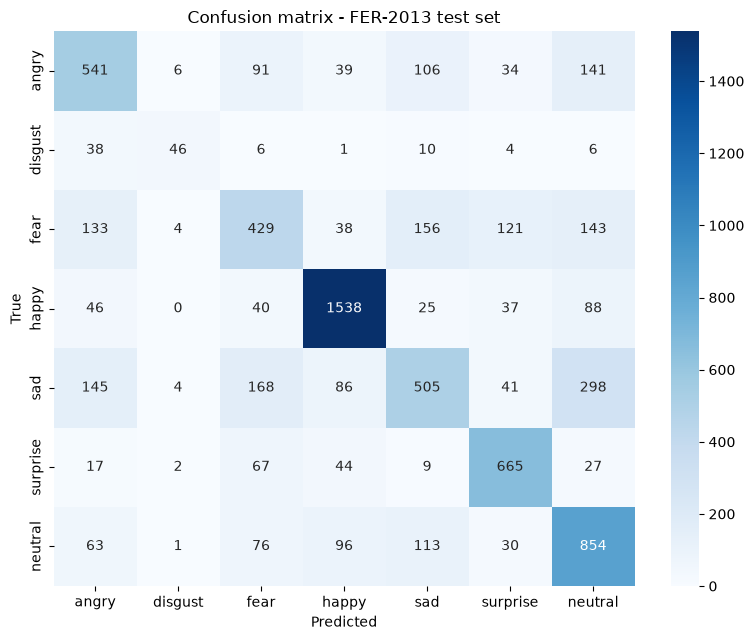

In [9]:
import seaborn as sns
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=config.EMOTIONS, yticklabels=config.EMOTIONS)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion matrix - FER-2013 test set')
plt.tight_layout(); plt.show()

## 4. Single-image inference

In [10]:
from src.predict import predict_array
import cv2
img = cv2.imread(os.path.join(config.SAMPLES_DIR, 'sample_happy.png'))
res = predict_array(model, img)
print('Prediction :', res['emotion'], f"({res['confidence']*100:.2f}%)")
for e, p in sorted(res['probabilities'].items(), key=lambda kv: -kv[1]):
    print(f'  {e:>9}: {p*100:6.2f}%')

Prediction : happy (99.58%)
      happy:  99.58%
   surprise:   0.34%
       fear:   0.04%
    neutral:   0.03%
      angry:   0.01%
        sad:   0.00%
    disgust:   0.00%
